# Anchorage Through the Seasons
## Cloud-Native Geospatial Analysis Using Sentinel-2

A personal remote-sensing case study of my hometown, Anchorage, Alaska. I investigated seasonal vegetation greenness and snow and ice across the municipality in 2025, contrasting three community study extents with the surrounding predominantly natural territory.

**8 acquisition dates · 4 non-overlapping land regions · 4,359.425 km² of vector-defined land · 43.59 million fixed 10 m grid cells**

The project combines satellite imagery, computational geometry, spectral indices, quality masking and cloud-native raster access. The results below are descriptive observations, not a trained machine learning model or a continuous reconstruction of the year.

**Highlights:** Municipal mean NDVI reached 0.741 on July 27 among usable snow-free observations. On September 30, the snow/ice proxy reached its lowest observed municipal value (19.24% of usable NDSI observations). The March 29 observation of Girdwood–Alyeska illustrates why coverage matters: only 342 of its 46,077 land cells were scientifically usable.

**Reading this notebook:** Maps, charts and calculated table outputs are embedded for viewing without executing code. The optional Python examples use the small [regional results CSV](results/anchorage_2025_seasonal_regional_statistics.csv), not satellite rasters. The processing implementation is in [scripts/](scripts/); see the [README](README.md) for prerequisites and reproduction limits.

## 1. A municipality of contrasts
The Municipality of Anchorage includes extensive mountainous and glaciated landscapes as well as its populated communities. The three community study extents together make up approximately 8.49% of mapped-water-excluded municipal land. They are not impervious-surface measurements; the remaining region is predominantly, not exclusively, natural land.

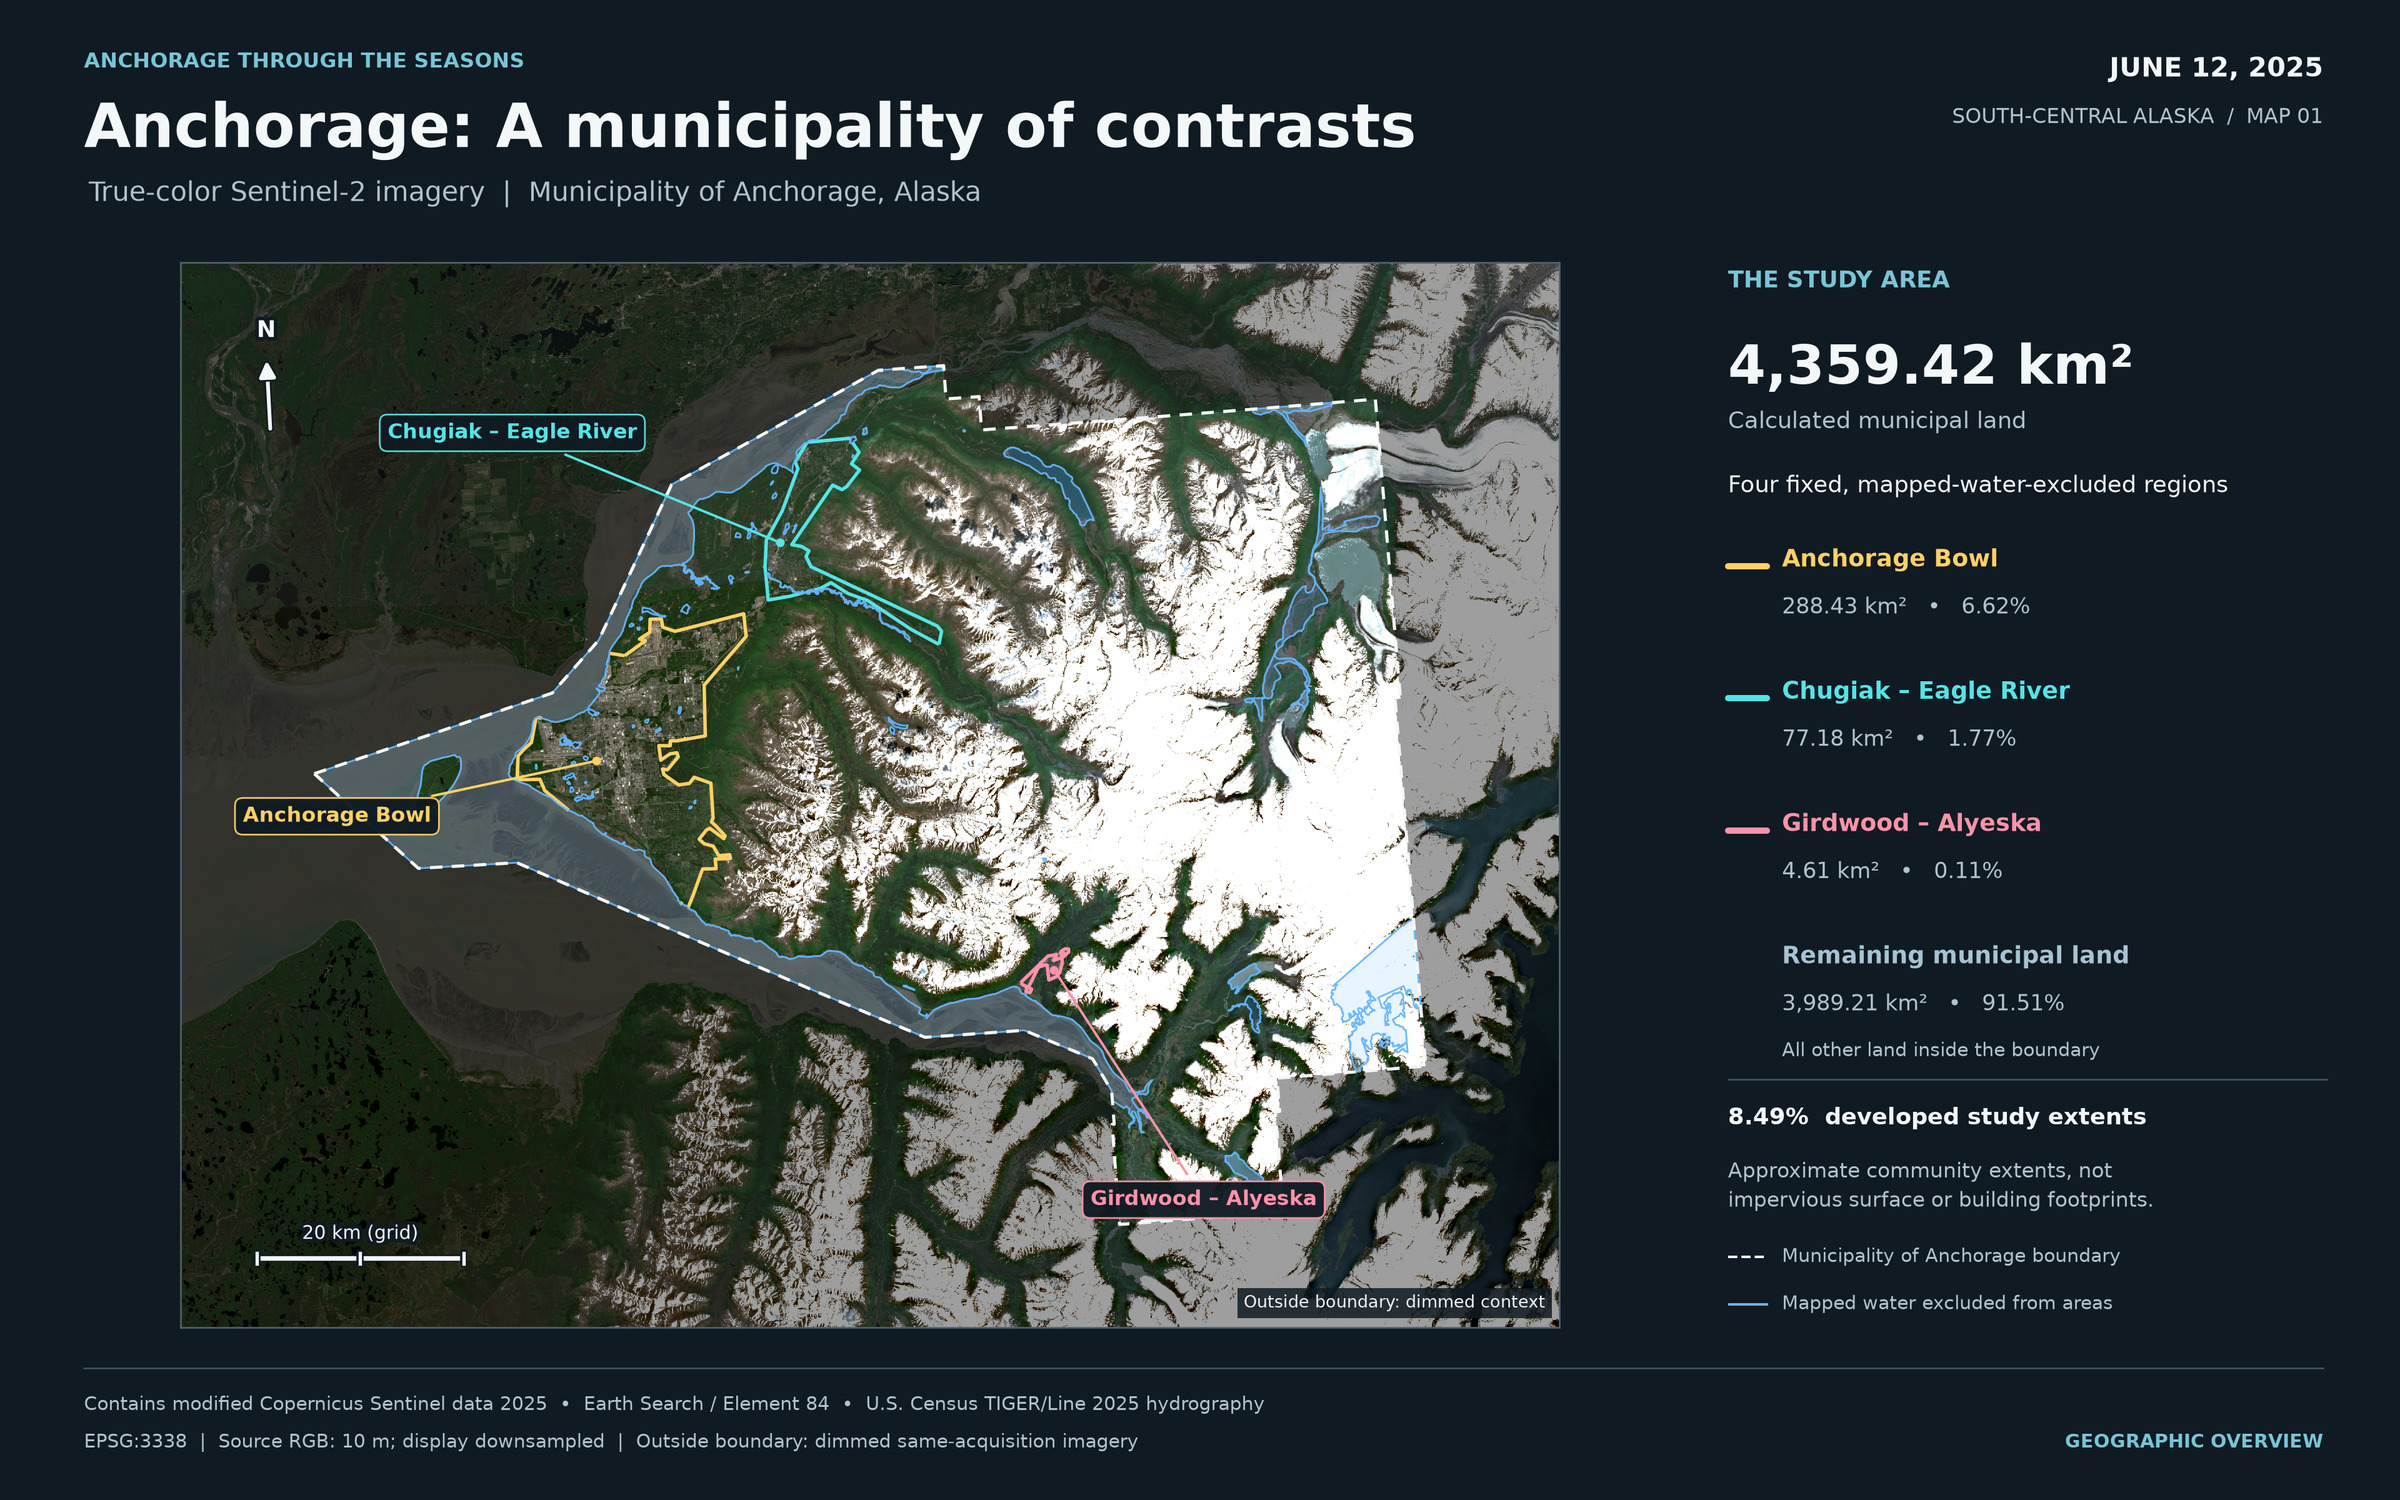

*Geographic overview, June 12, 2025. Study-region outlines are fixed across acquisitions. Contains modified Copernicus Sentinel data 2025.*

In [4]:
from pathlib import Path
import pandas as pd
from IPython.display import display

csv_path = Path("results/anchorage_2025_seasonal_regional_statistics.csv")
observations = pd.read_csv(csv_path, dtype={"date": str})
observations["date"] = pd.to_datetime(observations["date"], format="%Y%m%d")
assert observations.shape == (40, 50)
assert not observations.duplicated(["date", "region"]).any()
areas = observations.drop_duplicates("region").set_index("region")
areas = areas[["vector_land_km2", "land_pixels"]].copy()
areas["share_pct"] = 100 * areas.vector_land_km2 / areas.loc["All Municipal Land", "vector_land_km2"]
display(areas.round({"vector_land_km2": 3, "share_pct": 2}))

,vector_land_km2,land_pixels,share_pct
region,,,
Anchorage Bowl,288.428,2884256,6.62
Chugiak - Eagle River,77.175,771745,1.77
Girdwood - Alyeska,4.608,46077,0.11
Remaining Municipal Land,3989.214,39892151,91.51
All Municipal Land,4359.425,43594229,100.00


## 2. Eight views of 2025
The acquisition dates are February 7, March 29, May 23, June 12, July 27, August 11, September 30 and November 19. There are no selected observations in January, April, October or December. Acquisition groups were screened for footprint and spectral asset availability, then for pixel-quality indicators. Of 200 groups discovered, 62 qualified and were screened. Eight were selected for the detailed analysis.

The calendar-spaced chart points are actual observation dates; connecting lines guide the eye rather than represent measured daily values. Every percentage below has its own denominator. Usable land is relative to all fixed regional land, snow/ice is relative to NDSI-valid land, and green proxy is relative to NDVI-valid, conservatively snow-free land.

In [5]:
municipal = observations[observations.region == "All Municipal Land"].set_index("date").sort_index()
columns = {"snow_usable_pct_of_land": "NDSI usable (%)", "snow_ice_pct_of_snow_usable": "Snow/ice (%)", "ndvi_usable_pct_of_land": "NDVI usable (%)", "ndvi_mean": "Mean NDVI", "green_pct_of_ndvi_usable": "Green proxy (%)"}
display(municipal[list(columns)].rename(columns=columns).round(3))

,NDSI usable (%),Snow/ice (%),NDVI usable (%),Mean NDVI,Green proxy (%)
date,,,,,
2025-02-07,64.619,86.325,4.906,0.350,60.364
2025-03-29,47.695,53.546,16.276,0.336,57.635
2025-05-23,77.121,42.912,34.613,0.565,87.934
2025-06-12,92.380,36.809,48.678,0.687,91.729
2025-07-27,81.758,21.907,58.971,0.741,91.466
2025-08-11,76.448,20.783,56.487,0.694,86.749
2025-09-30,71.154,19.236,55.363,0.560,85.850
2025-11-19,58.180,88.879,3.180,0.278,36.823


### Interpreting the Results: February 7, 2025

The February observation provides a useful example of how to interpret the table. Each percentage must be understood in relation to its denominator.

| Measurement | Value | Interpretation |
|---|---:|---|
| NDSI usable | 64.62% | Approximately 65% of all municipal land was suitable for snow and ice analysis. |
| Snow / ice | 86.33% | Of that usable land, approximately 86% met the snow and ice detection criteria. |
| NDVI usable | 4.91% | Only approximately 5% of all municipal land qualified for vegetation analysis. |
| Mean NDVI | 0.350 | The average NDVI across that small usable subset was 0.350. |
| Green proxy | 60.36% | Approximately 60% of that small usable subset met the spectral greenness threshold. |

Although the green proxy was 60.36%, this does **not** mean that 60.36% of Anchorage's municipal land was green in February. Only approximately 4.9% of municipal land was usable for vegetation analysis, making the result unsuitable for characterizing vegetation across the municipality as a whole.

#### Why Was Vegetation Coverage So Low?

The underlying observation statistics provide additional context:

| Observation characteristic | Percentage of municipal land |
|---|---:|
| Imagery assignment | 99.99993% |
| Cloud coverage | 0.18870% |
| Shadow coverage | 34.19342% |
| NDVI usable coverage | 4.90587% |

Nearly the entire study area had satellite imagery assigned, and very little land was obscured by clouds. Missing imagery and clouds were therefore not the primary limitations.

Instead, two important factors reduced usable vegetation coverage:

- **Terrain shadows:** During winter, the low angle of the sun causes mountains to cast extensive shadows over surrounding terrain. These poorly illuminated surfaces can make reliable spectral measurements difficult.
- **Conservative snow exclusion:** Pixels identified as snow or ice by either NDSI or the Scene Classification Layer (SCL) were excluded from vegetation analysis. This prevents snow-covered surfaces from distorting the vegetation statistics.

This example illustrates an important distinction in remote sensing: having satellite imagery available for a geographic area does not necessarily mean that the entire area is suitable for a particular scientific measurement.

## 3. The growing season
NDVI is a spectral indicator of vegetation greenness. The maps deliberately exclude snow and ice detected by either the calculated NDSI rule or the satellite's Scene Classification Layer (SCL). Among usable observations, municipal mean NDVI increased from 0.336 on March 29 to 0.741 on July 27, then fell to 0.560 on September 30. On June 12, Chugiak–Eagle River had mean NDVI of 0.738 compared with 0.586 in Anchorage Bowl. These values describe the observed subset, not every part of each region.

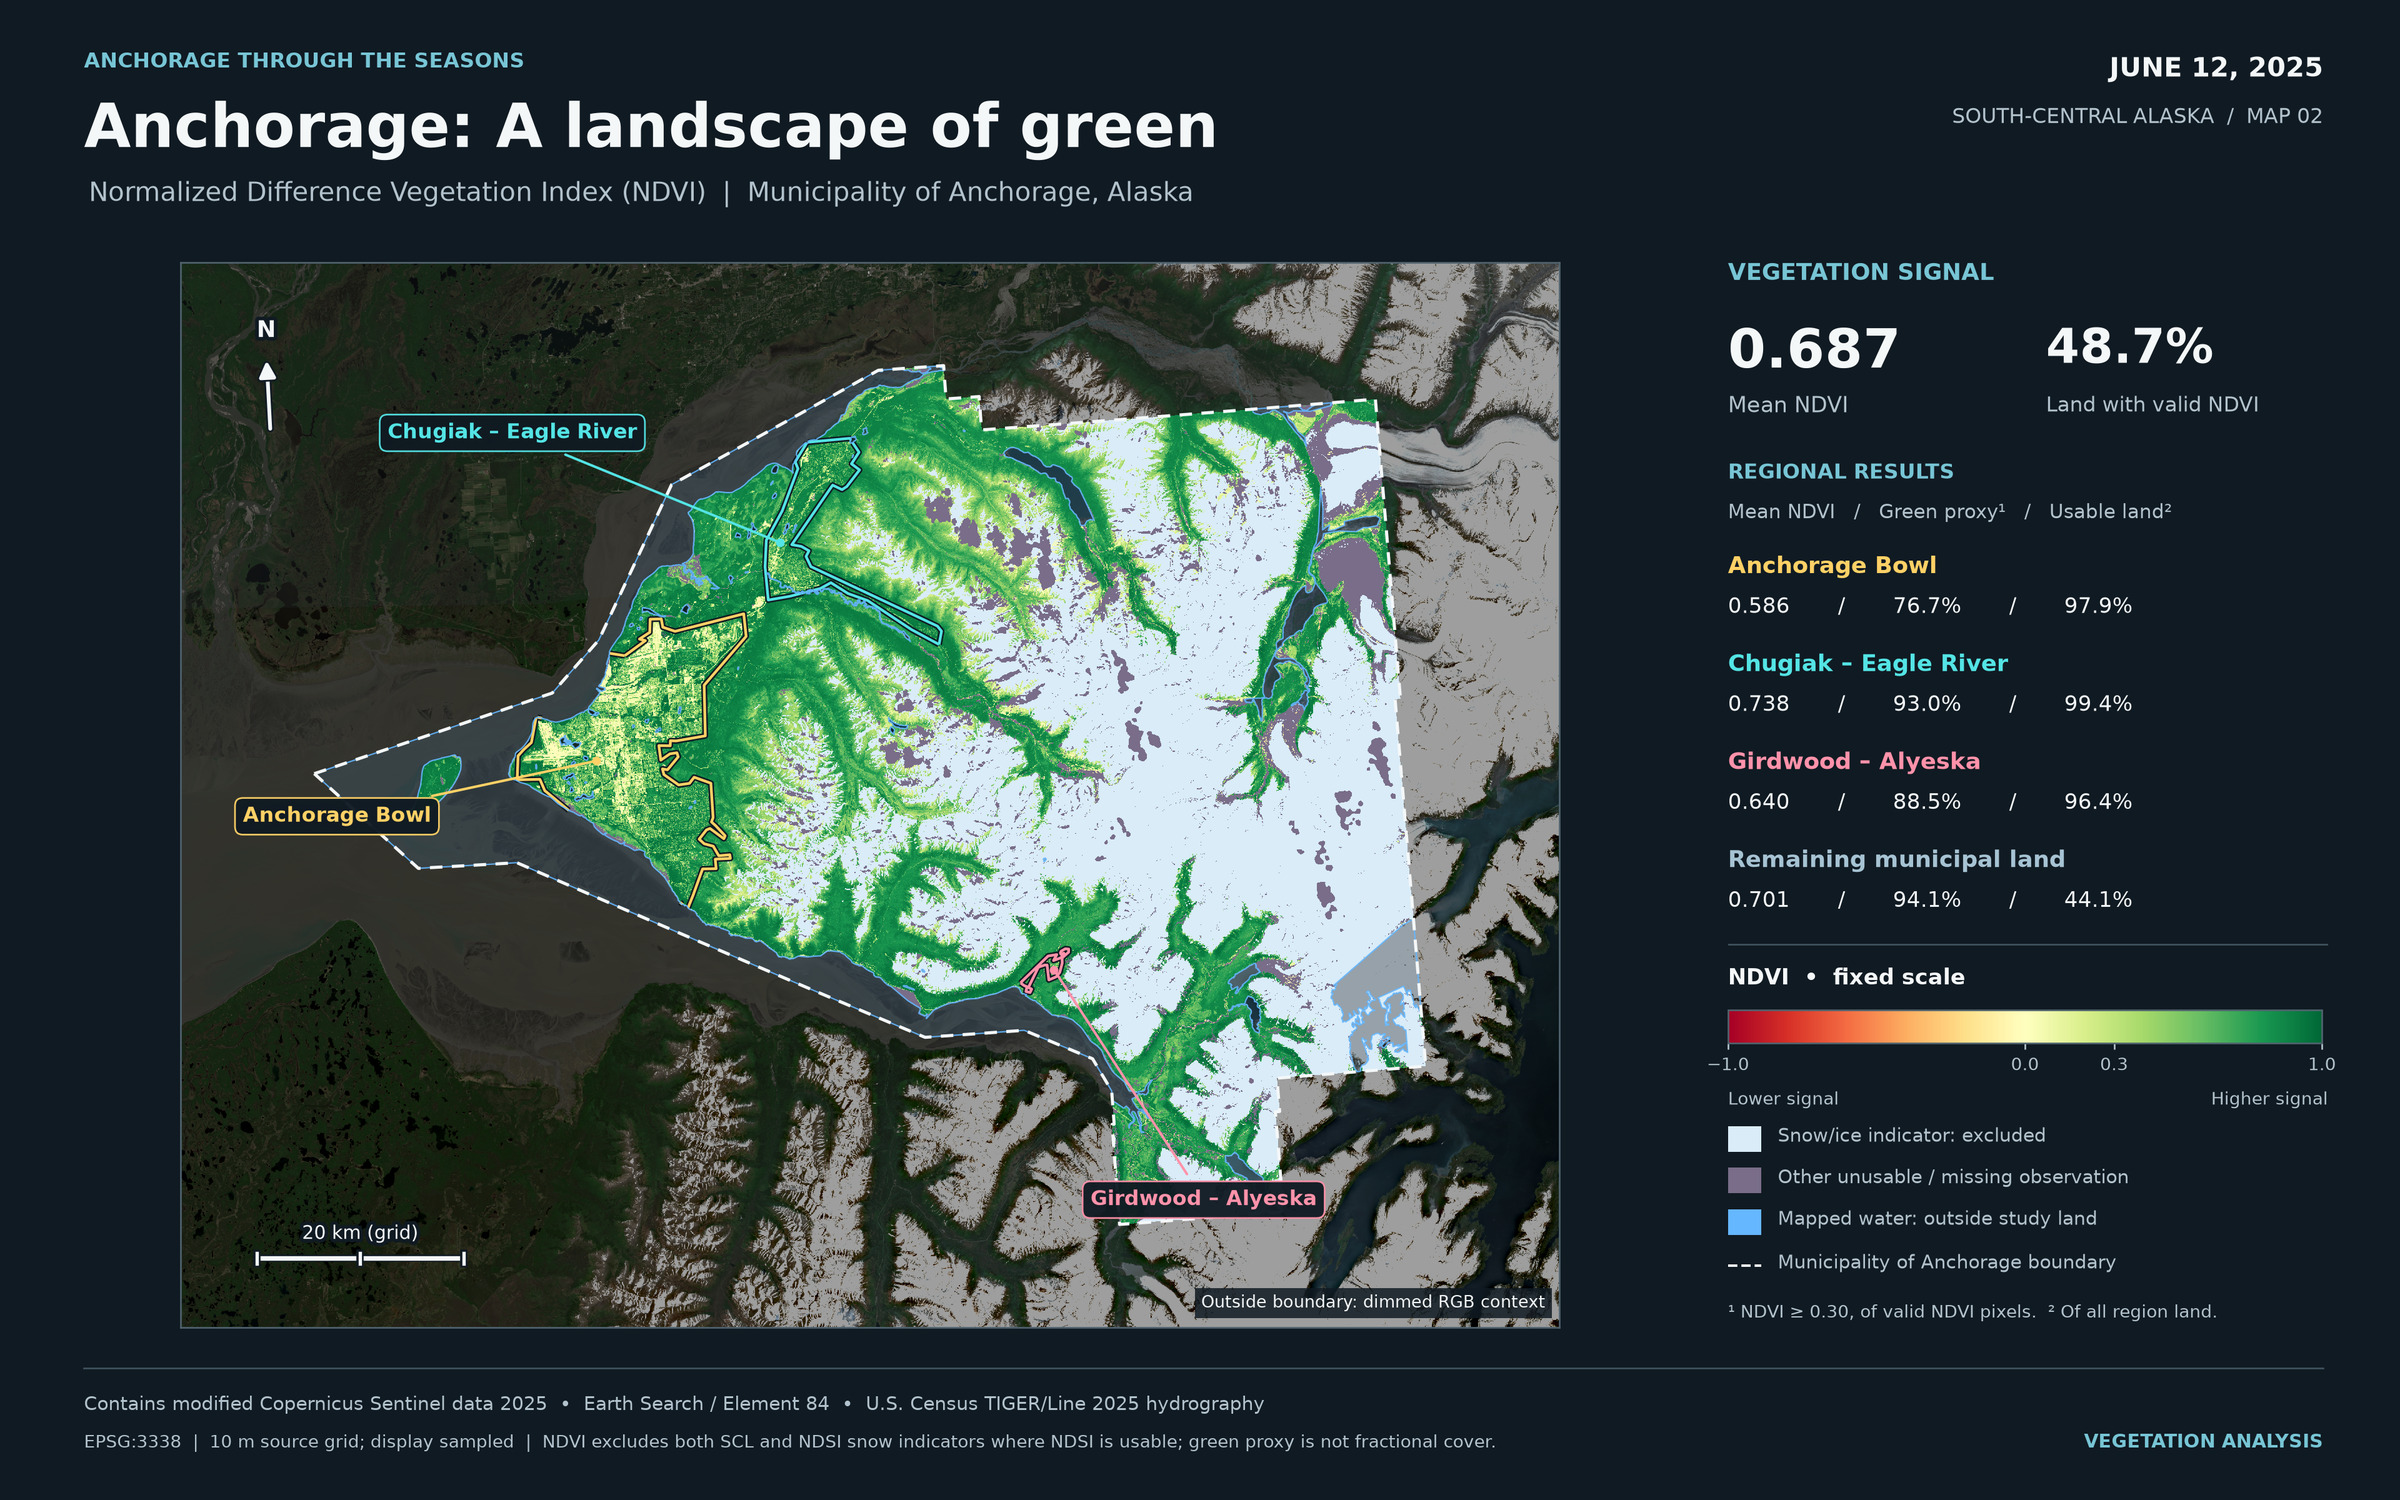

*June 12 vegetation index map; snow exclusion and other unusable land are distinguished. Contains modified Copernicus Sentinel data 2025.*

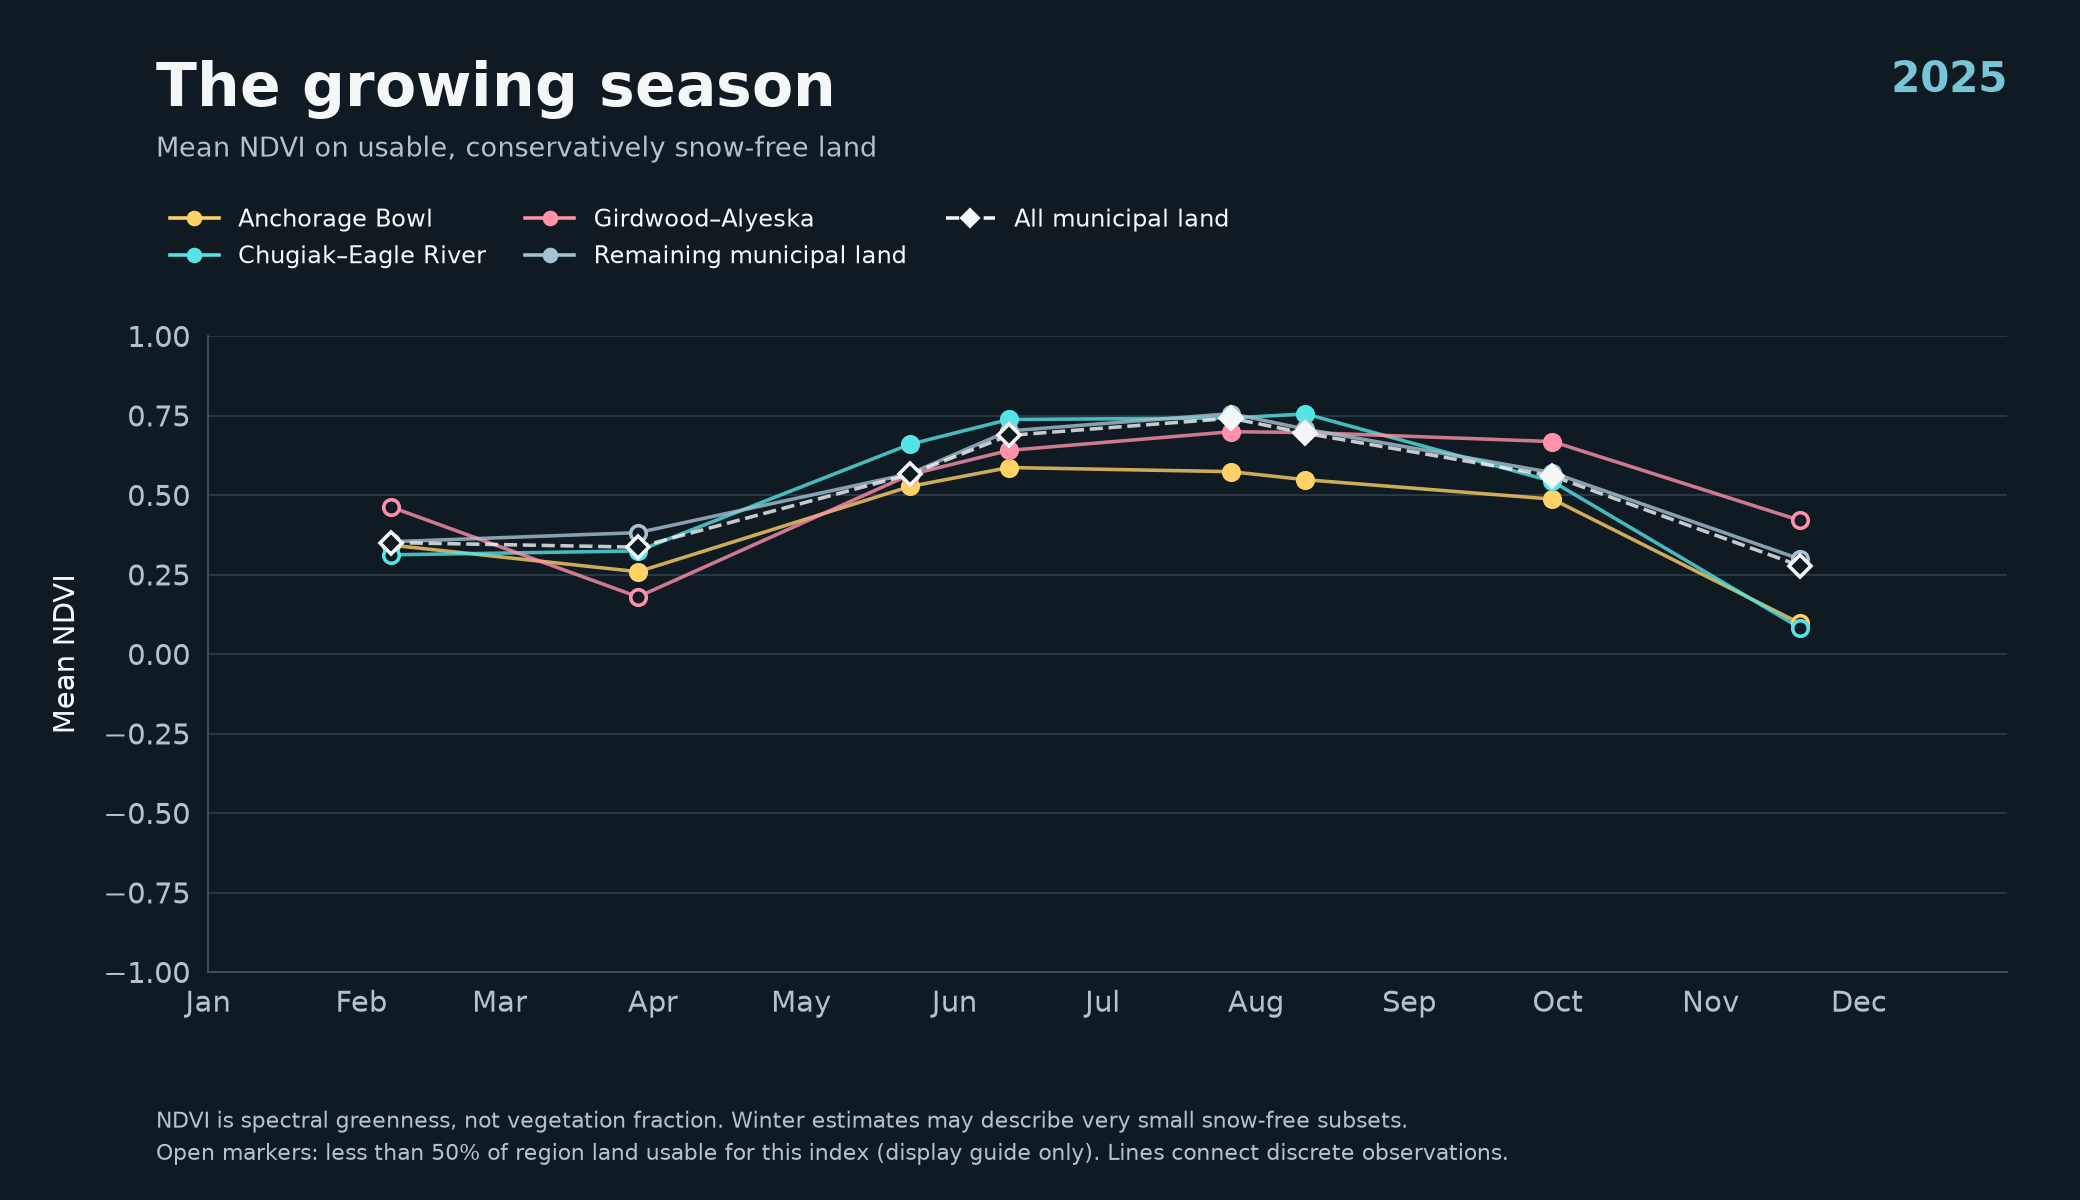

*Mean NDVI across eight selected acquisitions. Hollow markers flag usable coverage below 50%. Contains modified Copernicus Sentinel data 2025.*

The greenness proxy counts usable NDVI pixels at or above 0.30. It does not estimate fractional vegetation cover. For example, 60.36% of the February municipal NDVI-valid subset met this threshold, but only 4.91% of all municipal land was eligible for NDVI. It would be incorrect to say that 60.36% of Anchorage was green in February.

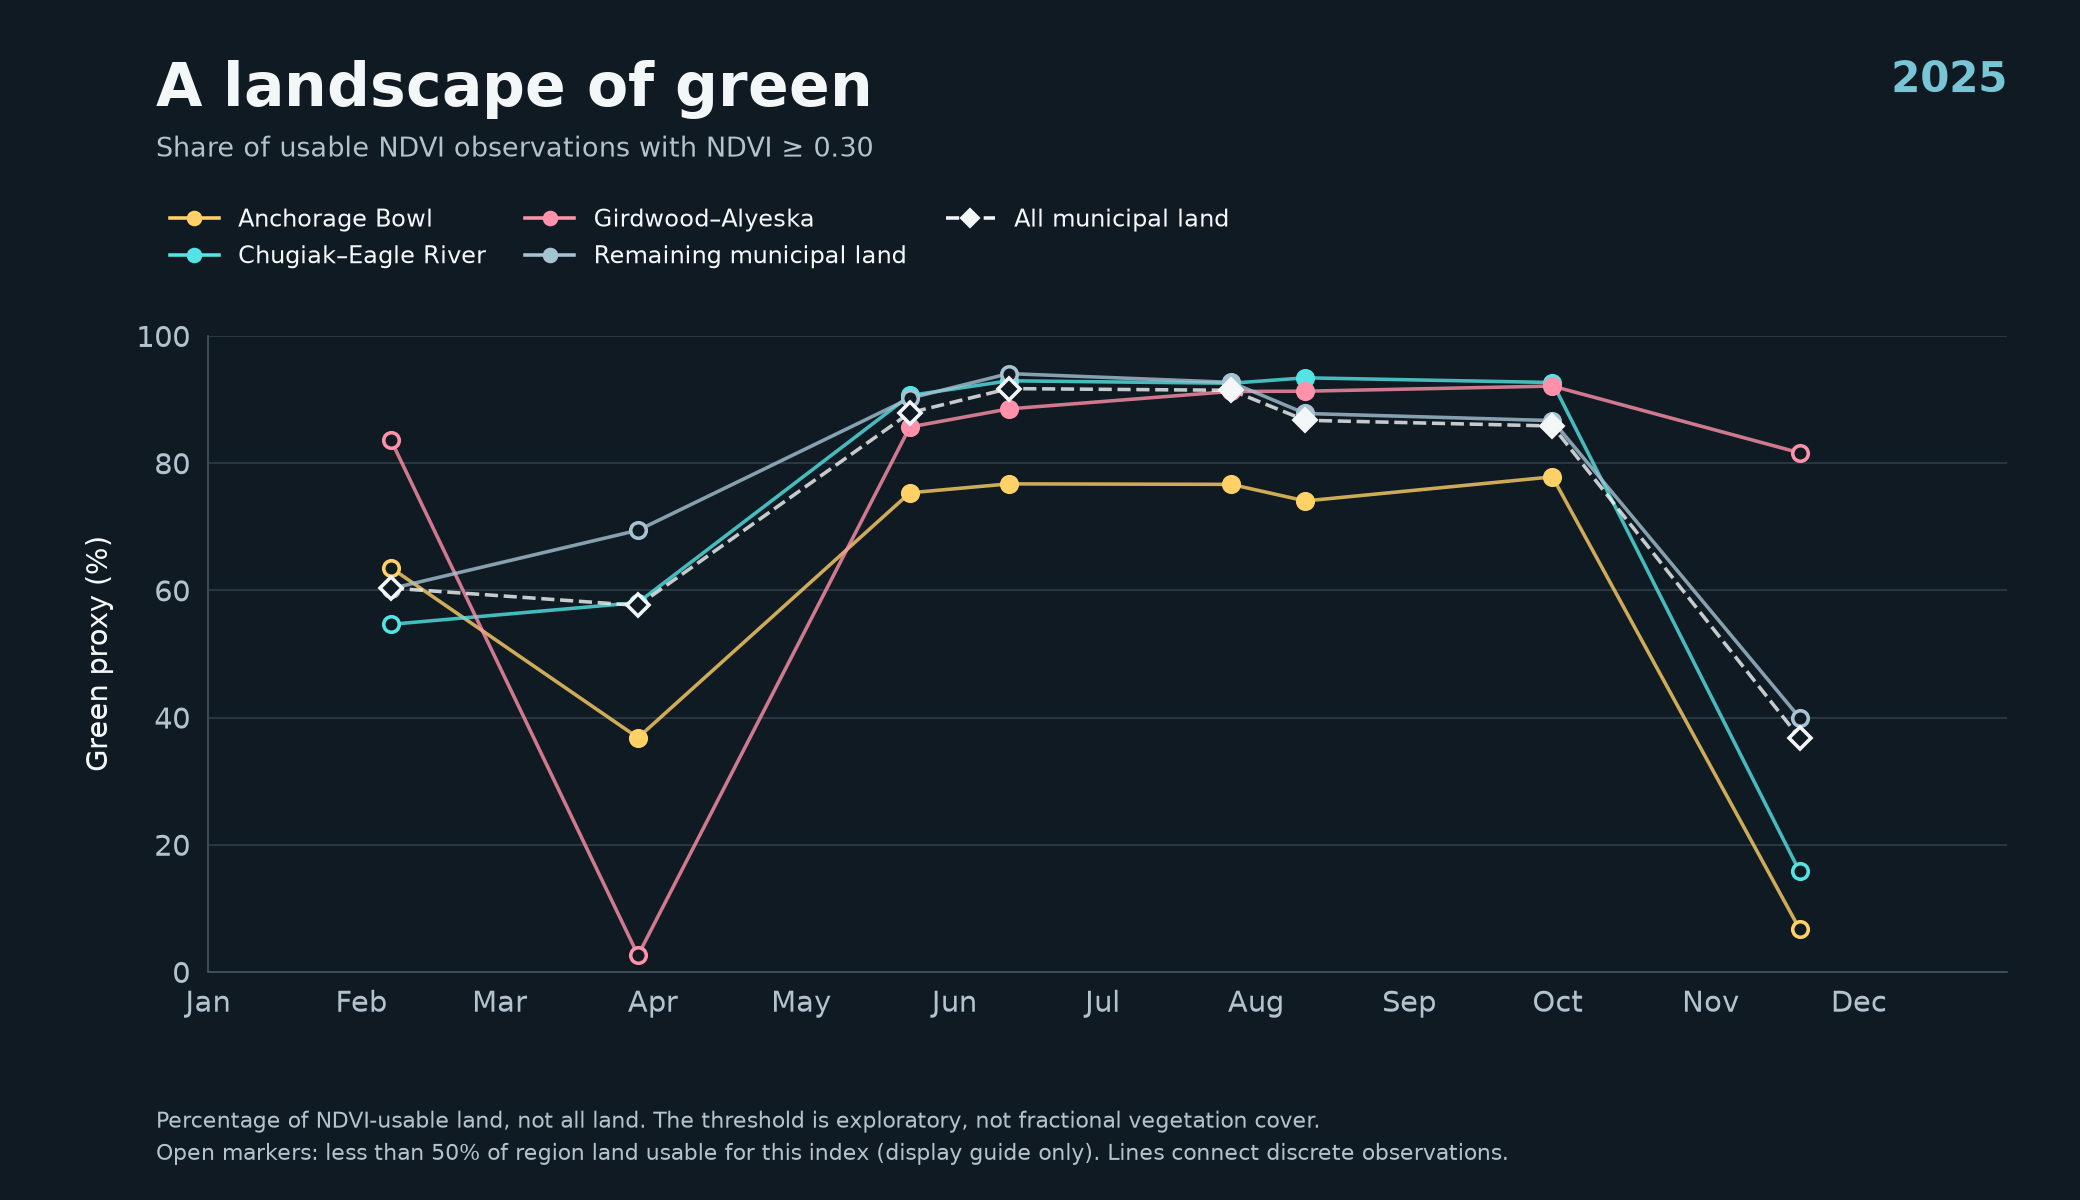

*Threshold-based greenness among usable NDVI observations. Contains modified Copernicus Sentinel data 2025.*

## 4. Where winter lingers
Snow and ice declined during spring and summer and returned in November. The contrast between Anchorage Bowl and the remaining municipal territory is especially visible in June: 0.01% versus 40.47% of their respective usable NDSI observations met the snow/ice rule. On November 19, 88.88% of the municipality's NDSI-valid observations met the rule, while only 58.18% of total study land was NDSI-valid.

The rule does not separate seasonal snow from glacial ice. Differences between community and surrounding land are descriptive; elevation, topography, glaciers, vegetation, weather and observation availability are not controlled for.

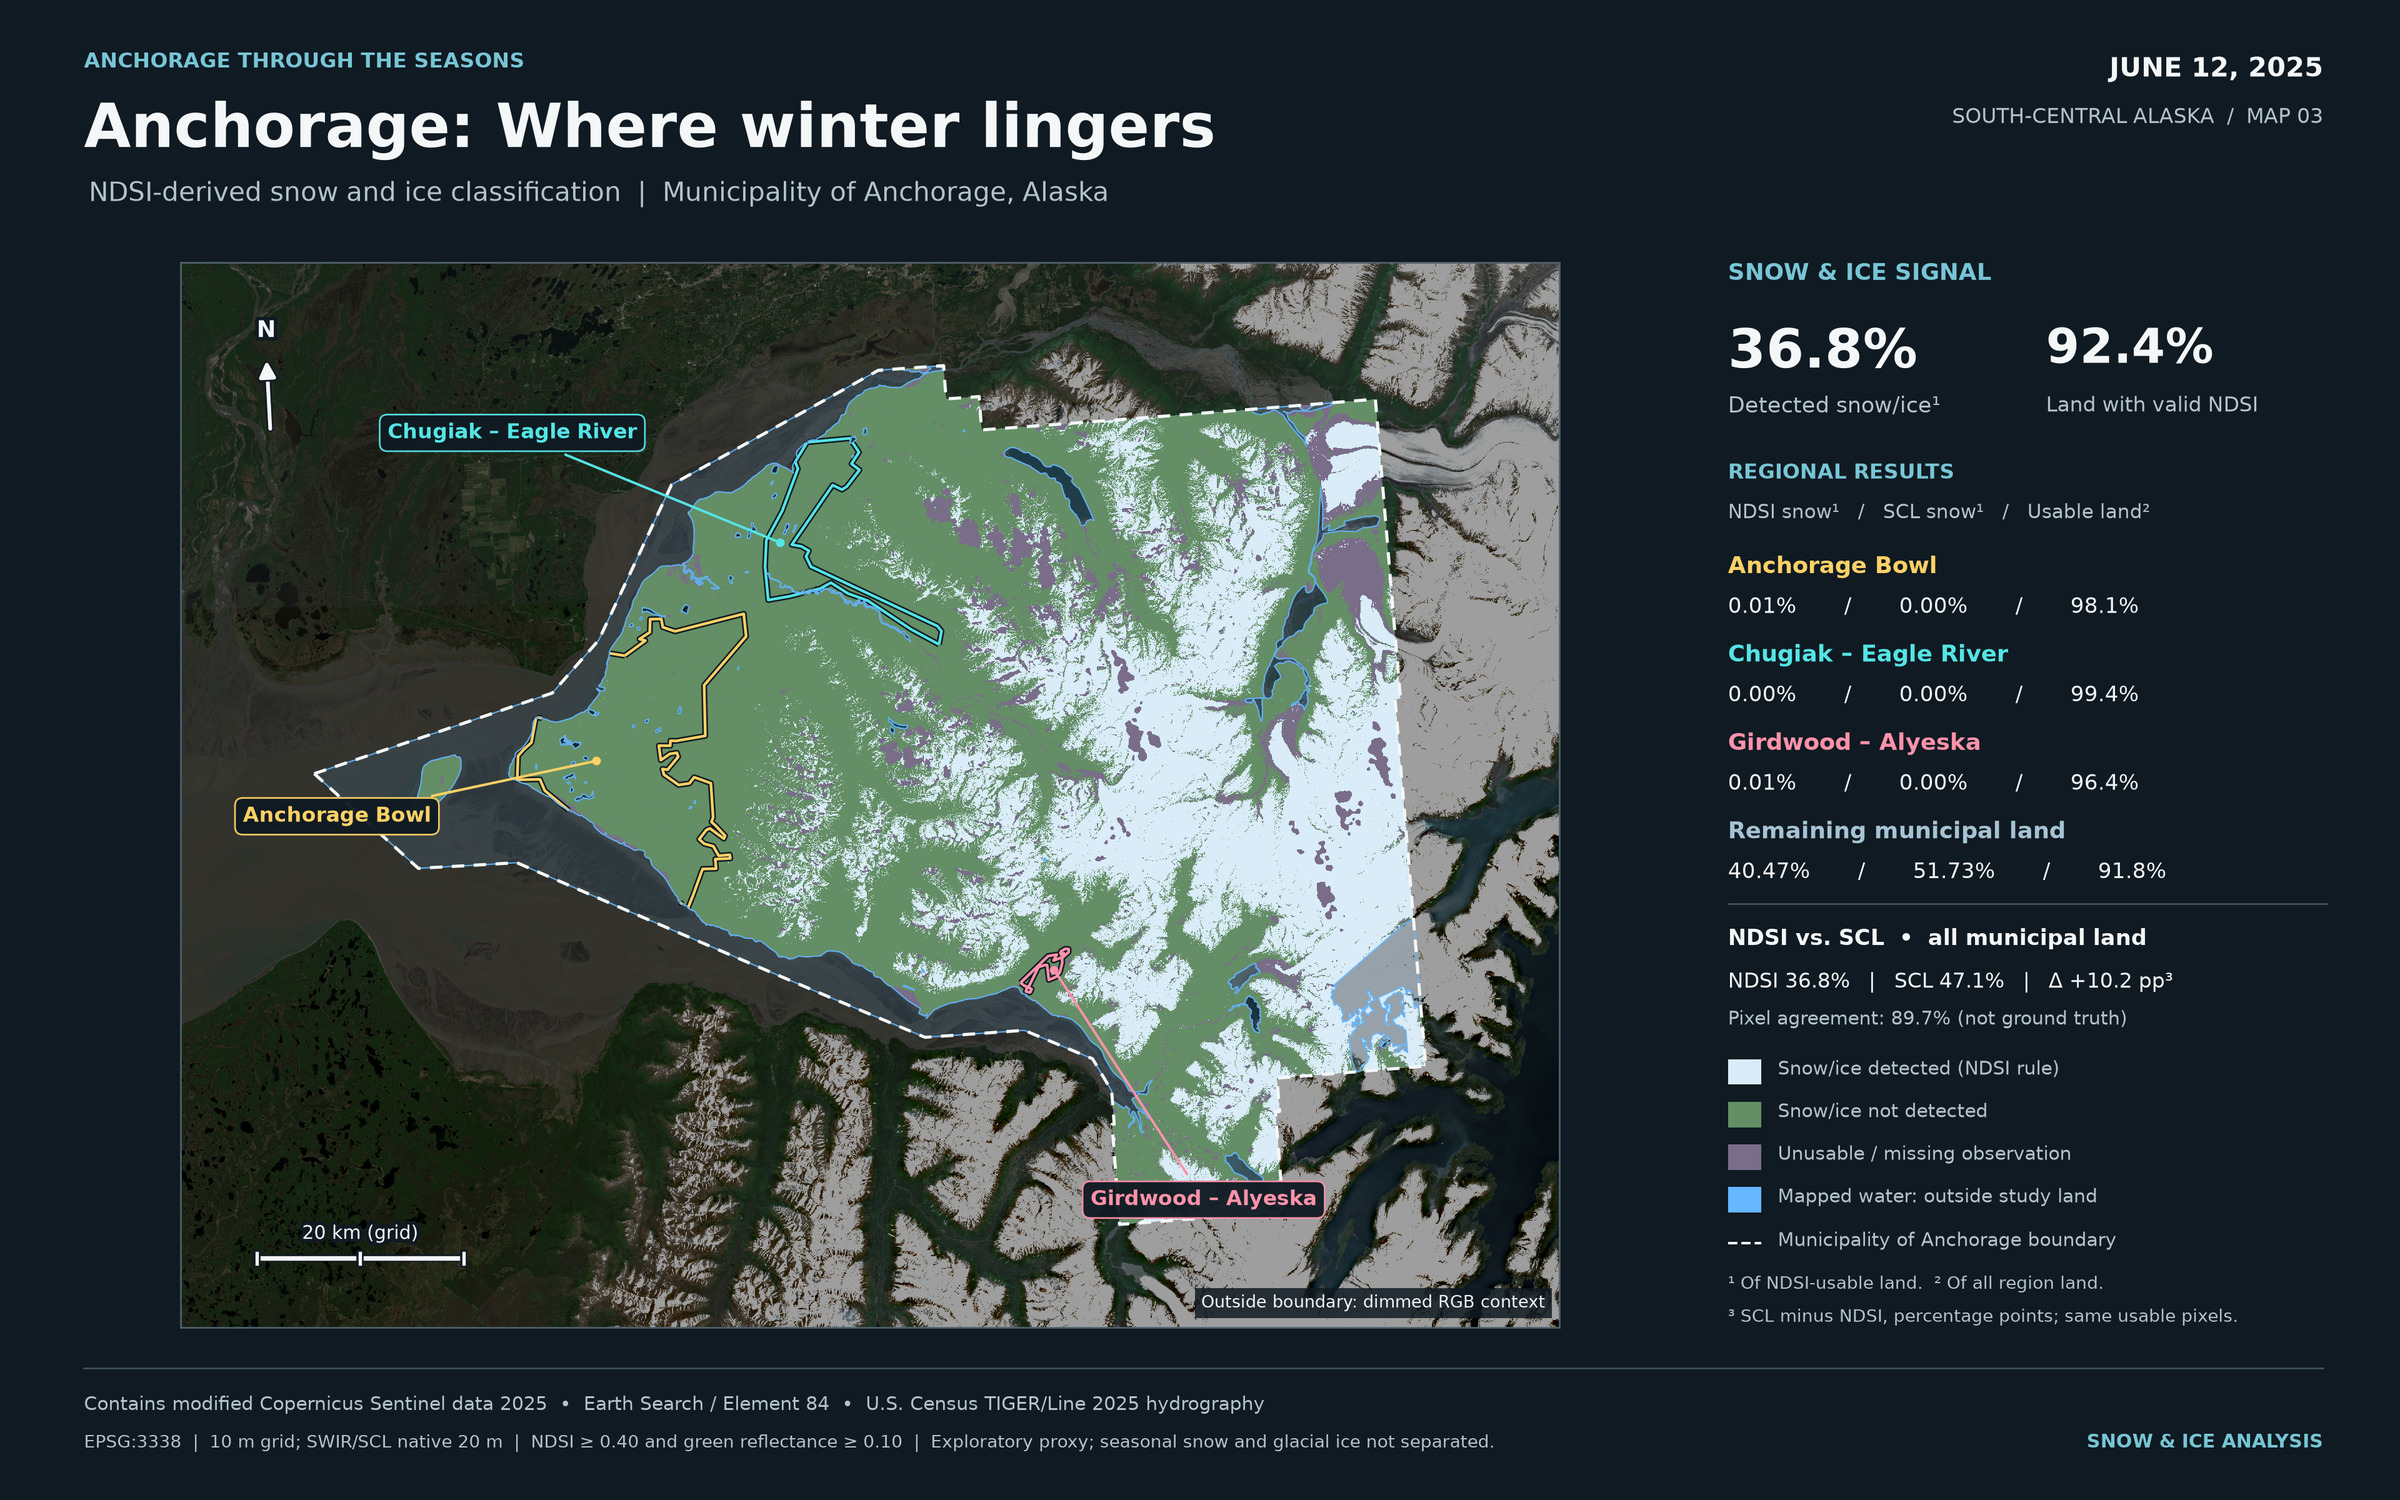

*June 12 snow and ice proxy map, with NDSI/SCL comparison. Contains modified Copernicus Sentinel data 2025.*

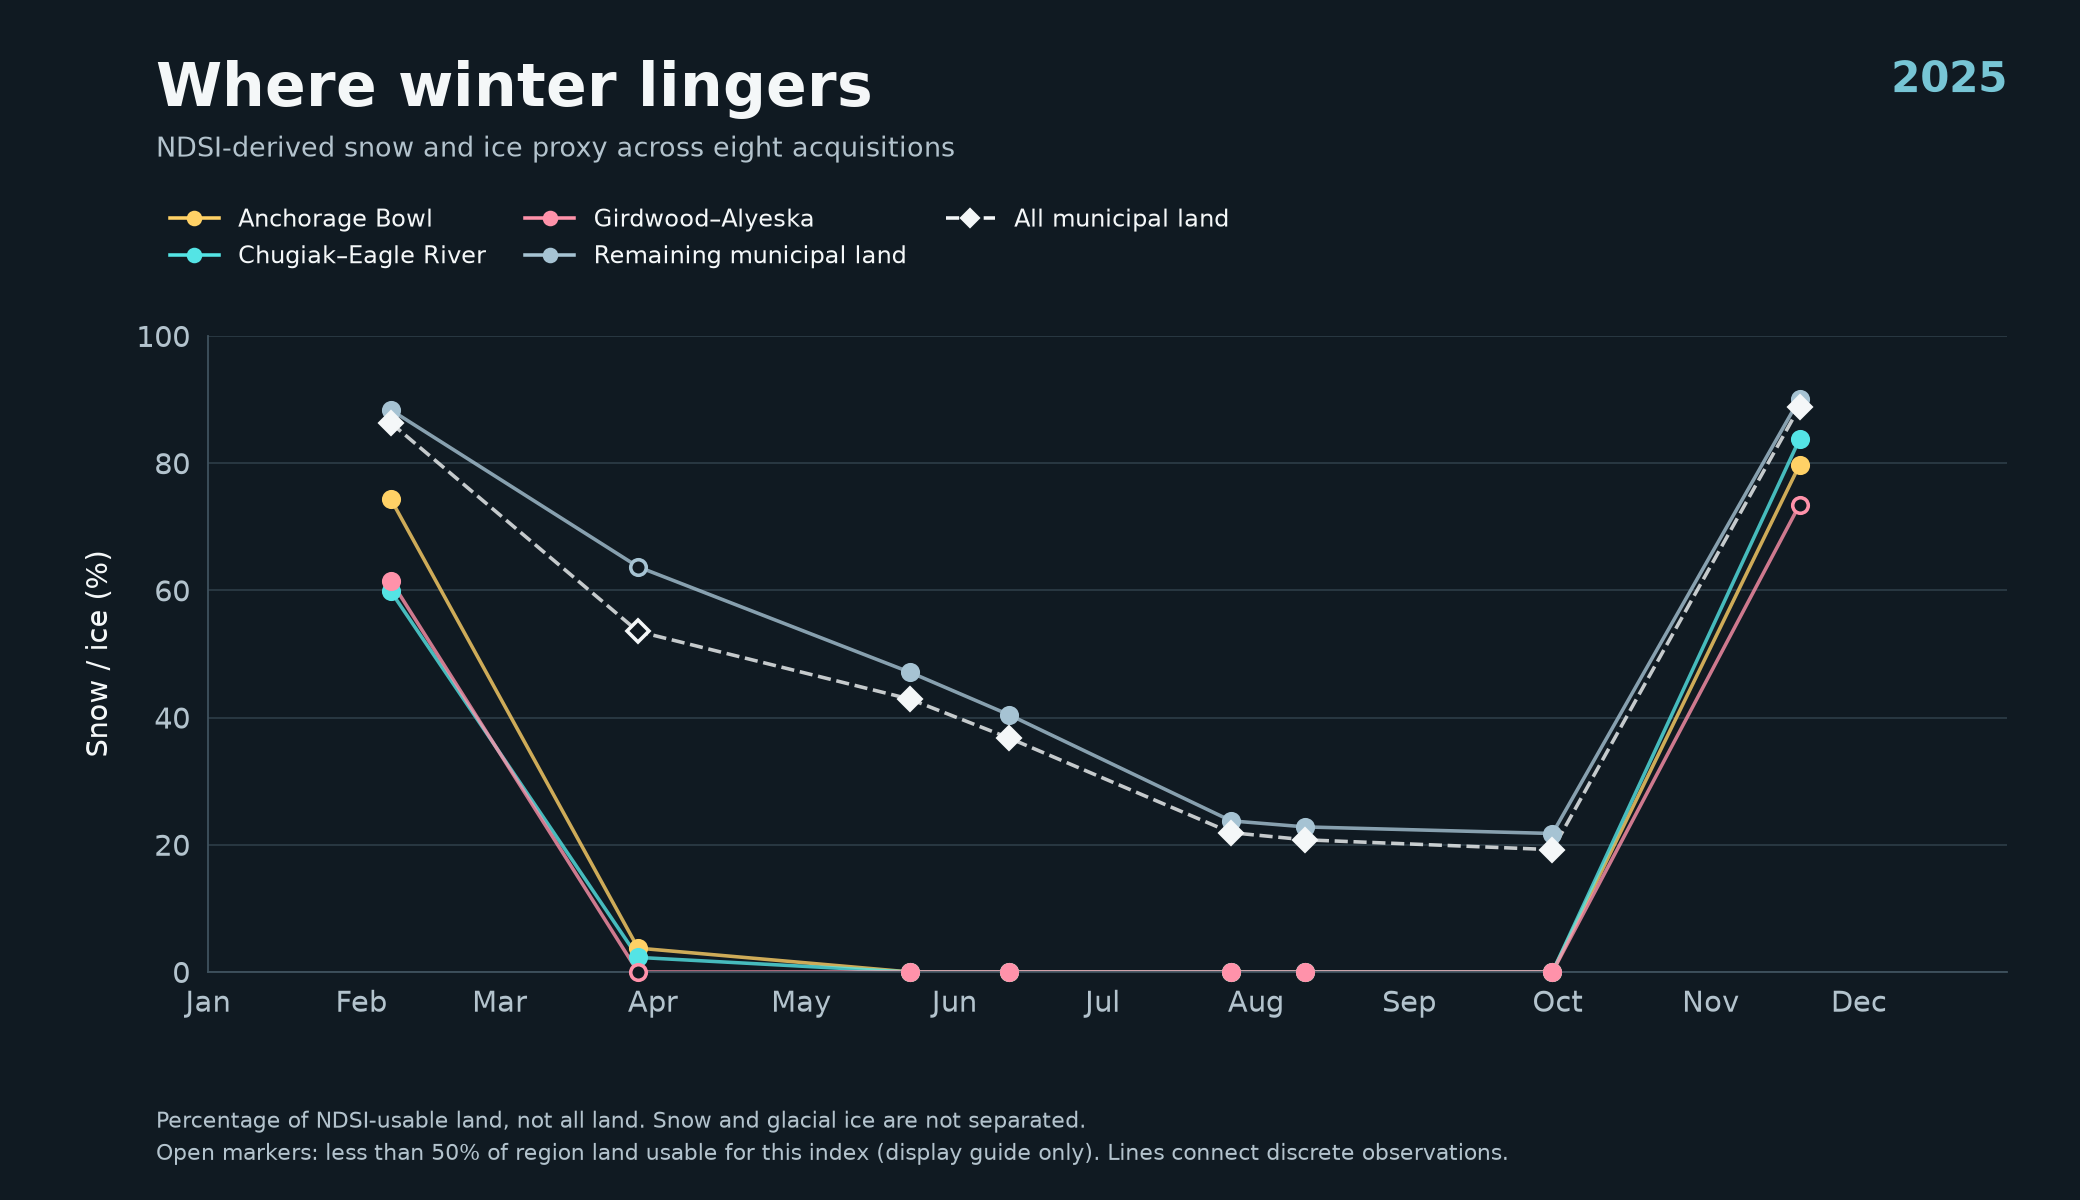

*Snow/ice proxy as a fraction of NDSI-valid observations, not total regional land. Contains modified Copernicus Sentinel data 2025.*

## 5. What the satellite can observe
Geographic coverage is not the same as scientific usability. All dates have almost complete assigned imagery, but clouds, shadows, unclassified observations, invalid spectral measurements and snow exclusion can substantially reduce the usable subset. In February and November the municipal shadow shares were about 34.19% and 40.14%, respectively, despite little cloud contamination. March 29 municipal cloud share was 49.93%, leaving 47.69% of municipal land NDSI-valid and 16.28% NDVI-valid.

Hollow chart markers and the 50% guide are presentation cautions, not validated representativeness thresholds. Even high coverage does not guarantee an unbiased sample.

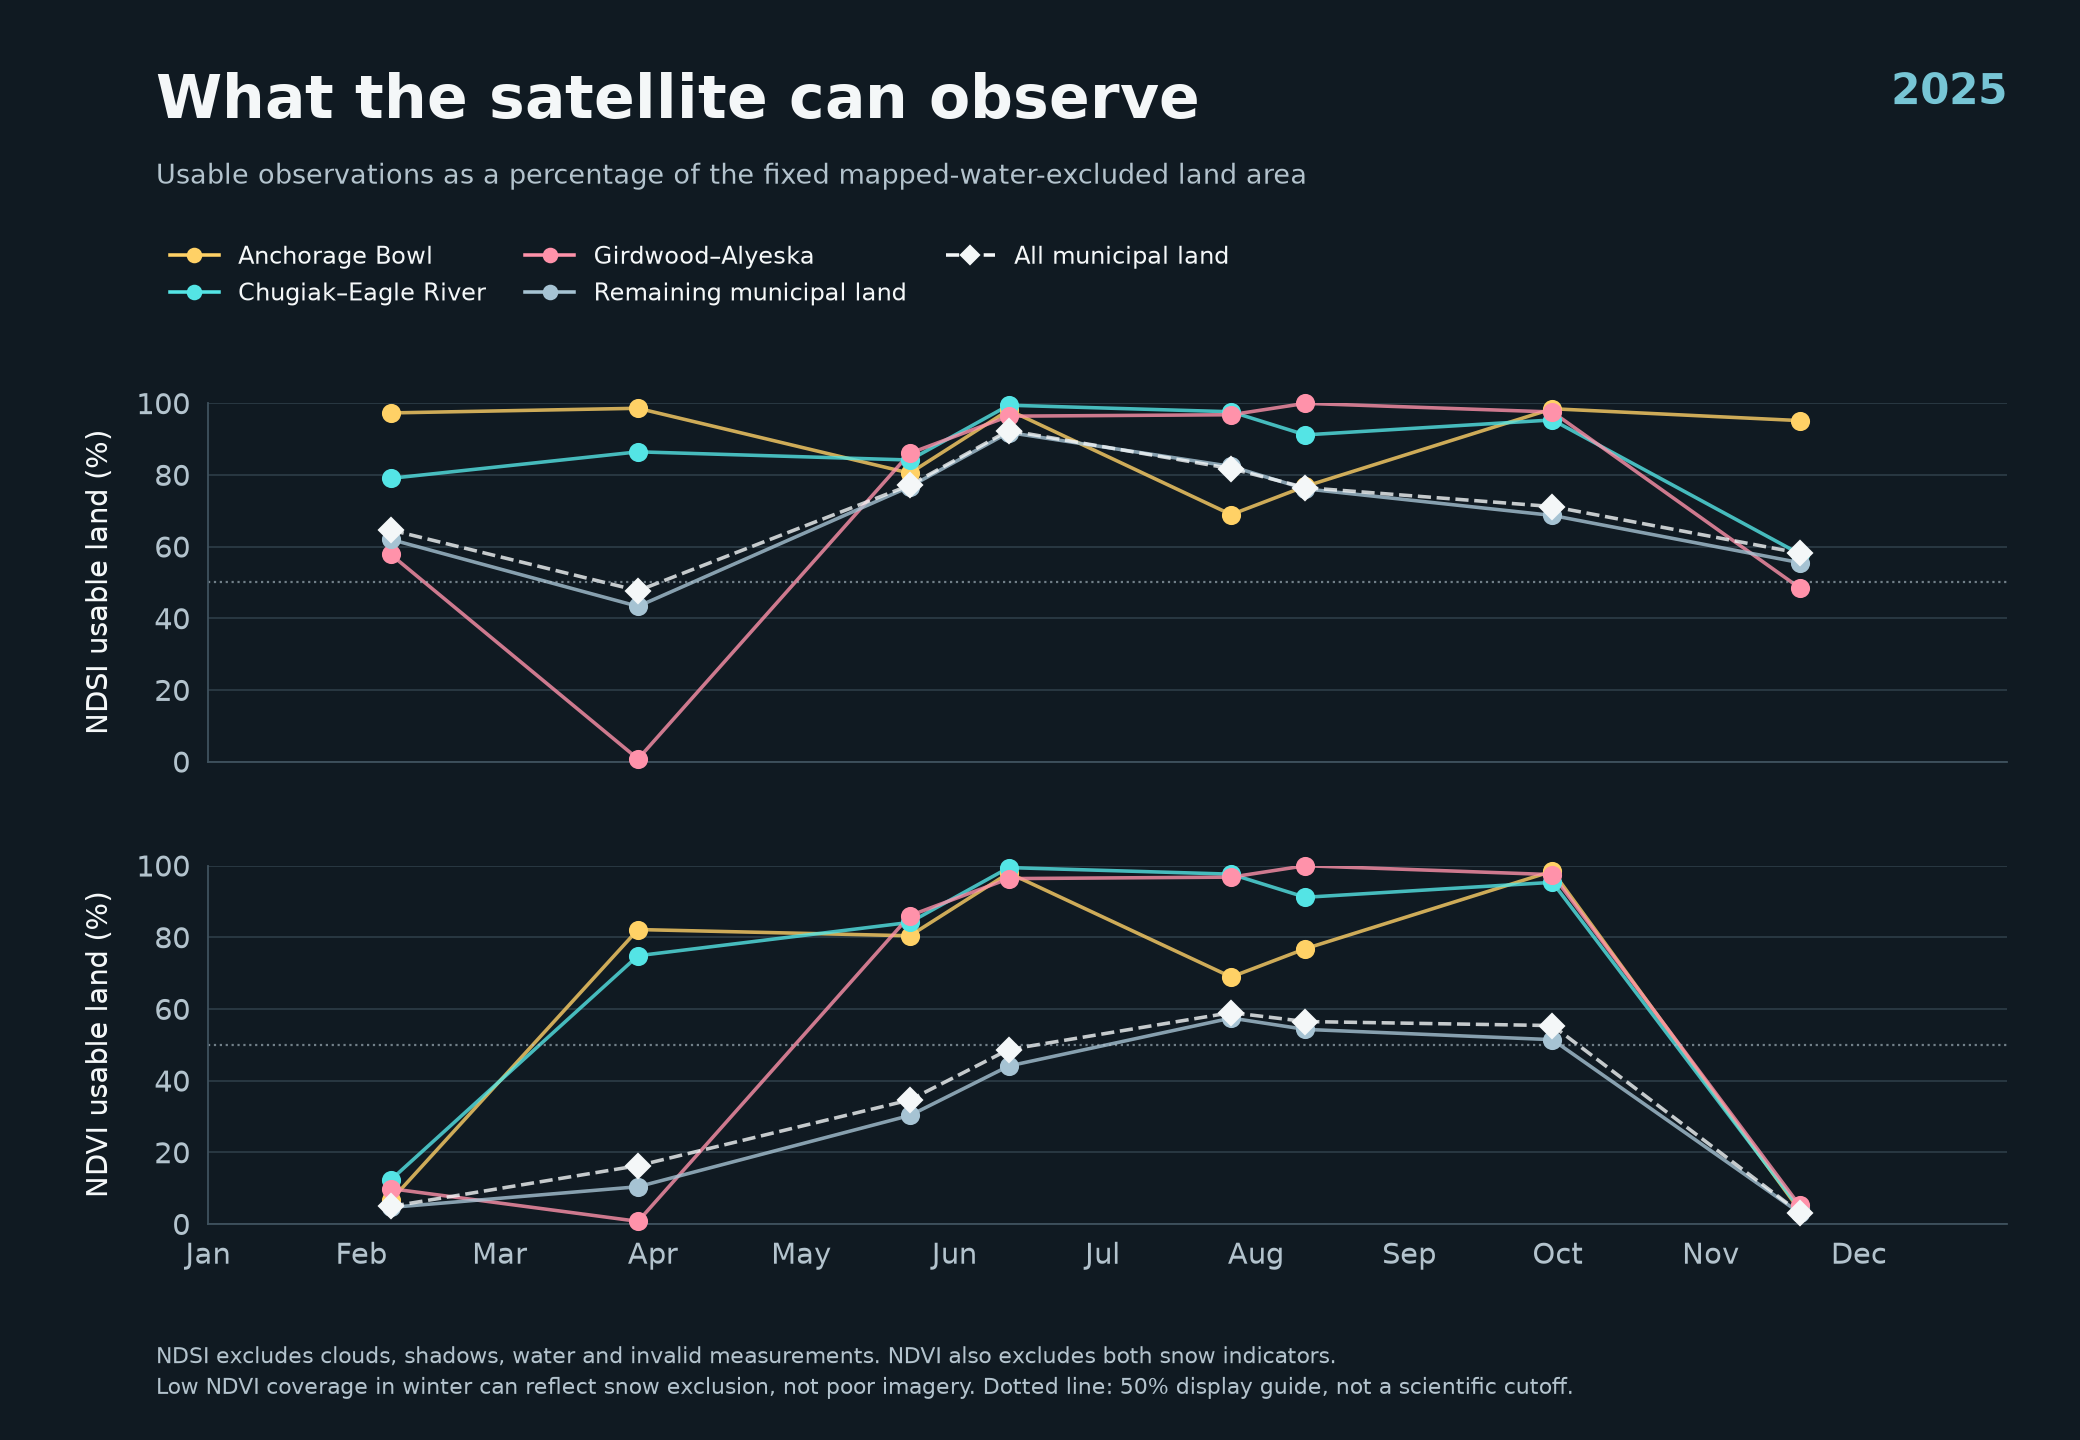

*Usable land coverage for NDSI and NDVI, shown separately. Contains modified Copernicus Sentinel data 2025.*

### A particularly important example: Girdwood–Alyeska, March 29
All 46,077 fixed land cells had assigned imagery. The quality filter excluded 34,154 cloud/cirrus cells, 11,573 unclassified cells, and 8 SCL water cells. Only 342 cells (0.74224% of regional land, approximately 0.0342 km²) were usable for both indices. Zero met the snow rule; nine met the greenness threshold. The resulting 2.63% green proxy and 100% NDSI/SCL agreement are valid calculations on this tiny observed subset, not reliable regional measurements. The low-coverage point should not be interpreted as a representative seasonal trend.

In [6]:
girdwood = observations.loc[(observations.date == "2025-03-29") & observations.region.str.startswith("Girdwood")].iloc[0]
counts = pd.Series({"Cloud/cirrus": girdwood.cloud_pixels, "Unclassified": girdwood.scl_07_unclassified_pixels, "SCL water": girdwood.scl_water_pixels, "Usable NDSI and NDVI": girdwood.ndvi_valid_pixels}, name="Cells")
assert counts.sum() == girdwood.land_pixels
assert girdwood.ndsi_valid_pixels == girdwood.ndvi_valid_pixels
review = counts.to_frame()
review["Share of regional land (%)"] = 100 * review.Cells / girdwood.land_pixels
display(review.round(5))

,Cells,Share of regional land (%)
Cloud/cirrus,34154,74.12375
Unclassified,11573,25.11665
SCL water,8,0.01736
Usable NDSI and NDVI,342,0.74224


## 6. Technical methodology
### Spectral bands and reflectance
| Band | Wavelength region | Native pixel spacing | Use |
|---|---|---:|---|
| B02 | Blue | 10 m | True color |
| B03 | Green | 10 m | True color, NDSI |
| B04 | Red | 10 m | True color, NDVI |
| B08 | Near infrared (NIR) | 10 m | NDVI |
| B11 | Shortwave infrared (SWIR1) | 20 m | NDSI |

RGB display uses B04, B03, B02. All selected assets had the verified encoding below, where DN is the stored digital number:

$$\rho = DN \times 0.0001 - 0.1$$

The additive offset must be applied before ratios are calculated. NoData DN values are not reflectance measurements.

### Understanding the Reflectance Scale and Offset

Sentinel-2 stores reflectance measurements as unsigned integers called **Digital Numbers (DN)** rather than floating-point values. The scale factor of `0.0001` and offset of `-0.1` convert these encoded integers back into their intended surface reflectance values.

**Why multiply by 0.0001?**

Storing scaled integers is more storage-efficient than storing floating-point numbers while preserving a reflectance resolution of four decimal places. Multiplying by 0.0001 is equivalent to dividing by 10,000.

**Why subtract 0.1?**

Although physical reflectance cannot be negative, estimated reflectance can become slightly negative due to sensor noise, measurement uncertainty, and atmospheric correction, particularly over very dark surfaces.

By introducing an offset during encoding, Sentinel-2 can represent negative reflectance estimates using positive, unsigned integers. Subtracting 0.1 during decoding removes this offset and recovers the intended measurement.

| Stored DN | After scaling | Decoded reflectance |
|---:|---:|---:|
| 500 | 0.050 | -0.050 |
| 800 | 0.080 | -0.020 |
| 1,000 | 0.100 | 0.000 |
| 3,500 | 0.350 | 0.250 |
| 6,000 | 0.600 | 0.500 |
| 11,000 | 1.100 | 1.000 |

The native Sentinel-2 Level-2A encoding uses digital numbers from 1 to 32,767, with zero reserved for missing data. Consequently, a DN of zero should be treated as missing rather than decoded as negative reflectance.

**Is this a form of image normalization?**

No. This transformation does not enhance image contrast, compensate for shadows, equalize brightness between regions, or constrain pixel values to a range between zero and one. It is simply a linear transformation with a slope of 0.0001 and an intercept of -0.1.

**Why does this matter when calculating NDVI and NDSI?**

Although a common multiplicative scale factor would cancel out when calculating a normalized difference index, the additive offset does not cancel out of the denominator. Therefore, calculating these indices directly from the encoded digital numbers would produce incorrect results.

Ultimately, this operation is best understood as **converting a storage representation into a scientific measurement representation**, rather than modifying or enhancing the underlying satellite observations.

The scale and offset were verified for all eight Sentinel-2 acquisitions used in this investigation and should not be assumed to apply universally to every satellite imagery product.

### NDVI and NDSI

$$NDVI = \frac{\rho_{B08}-\rho_{B04}}{\rho_{B08}+\rho_{B04}}$$

Vegetation generally absorbs red wavelengths and reflects near-infrared light; higher NDVI often corresponds to stronger greenness. The exploratory green proxy is NDVI $\geq 0.30$ on valid NDVI observations.

$$NDSI = \frac{\rho_{B03}-\rho_{B11}}{\rho_{B03}+\rho_{B11}}$$

Snow typically reflects green light more strongly than SWIR. The snow/ice rule requires NDSI $\geq 0.40$ and green reflectance $\geq 0.10$. The thresholds are exploratory and not calibrated against local ground observations. For the nonnegative reflectances accepted here both indices lie between -1 and +1.

### Scene Classification Layer and quality masking
| SCL | Class | Initially eligible? |
|---:|---|---|
| 0 | NoData | No |
| 1 | Saturated/defective | No |
| 2 | Terrain/topographic shadow | No |
| 3 | Cloud shadow | No |
| 4 | Vegetation | Yes |
| 5 | Nonvegetated surface | Yes |
| 6 | Water | No |
| 7 | Unclassified | No |
| 8 | Medium-probability cloud | No |
| 9 | High-probability cloud | No |
| 10 | Thin cirrus | No |
| 11 | Snow/ice | Yes for NDSI |

Source provenance and spectral completeness are required. Index-specific reflectances must be finite and nonnegative, and the sum of the relevant bands must exceed 0.0001. NDVI additionally requires valid NDSI and excludes any snow/ice detected by either NDSI or SCL. Invalid observations remain missing rather than zero. Low winter NDVI coverage can therefore reflect intentional snow exclusion even in otherwise useful imagery.

### Spatial framework and mosaicking
The QGIS display project uses EPSG:2964 (NAD27 / Alaska Albers, US survey feet); earlier local raster exercises used UTM Zone 6N (EPSG:32606). The fixed analysis grid uses EPSG:3338 (NAD83 / Alaska Albers, metres), with 10,739 columns and 8,299 rows at 10 m spacing. The area of each raster cell is $100\,m^2 = 0.0001\,km^2$. B11 and SCL are nearest-neighbour resampled from native 20 m data; this does not create independent 10 m snow observations.

GeoPandas and Shapely support clipping, union, intersection, water subtraction and validation of the study polygons; pyproj handles CRS transforms. A degenerate component in Remaining Municipal Land was repaired in memory with a reported area change of approximately 0.000016 m². Fixed region labels are mutually exclusive; the 43,594,229 raster land cells represent 4,359.4229 km². Vector and pixel-center rasterization areas differ slightly.

The source imagery was discovered using Earth Search STAC. Scenes were prioritized by scene-level cloud metadata with deterministic ID tie-breaking; each assigned pixel takes its spectral bands and quality metadata from the same selected scene. This prevents arbitrary cross-scene band mixing but does not guarantee the best individual pixel in overlaps. Rasterio reprojects and mosaics onto the common grid and creates tiled COGs with overviews. The project reported full-resolution pixel-equality checks for the COG conversion, as well as raster, geometry and regional accounting checks.

### Cloud-native demonstration
A separate June COG was stored in private AWS S3 and accessed in QGIS and through Rasterio/Boto3. A 200 × 200 pixel window (approximately 2 km × 2 km) around downtown Anchorage was retrieved without reading the full raster array. The COG format supports targeted access and multiresolution display; exact network transfer volume was not measured. Seasonal processing was performed locally using public source imagery; the eight acquisitions were not uploaded to private S3. No custom STAC service or production cloud pipeline was deployed.

## 7. Measurement reference
Let $L$ be fixed regional land cells, $S$ valid NDSI cells, $V$ valid NDVI cells, $F$ conservative snow-free candidates, $N$ cells meeting the NDSI snow rule, $G$ cells meeting the green proxy and $A=0.0001\,km^2$ per grid cell.

| Measurement | Definition |
|---|---|
| NDSI usable % | $100S/L$ |
| Snow / ice % | $100N/S$ |
| NDVI usable % | $100V/L$ |
| Mean NDVI | Sum of valid NDVI values divided by $V$ |
| Green proxy % | $100G/V$ |
| SCL snow % | SCL class 11 cells within $S$, divided by $S$, times 100 |
| NDSI–SCL agreement % | Binary snow decisions that agree within $S$, divided by $S$, times 100 |
| Cloud % | SCL classes 8, 9 and 10 within $L$, divided by $L$, times 100 |
| Shadow % | SCL classes 2 and 3 within $L$, divided by $L$, times 100 |
| Observed snow/ice area | $NA$ |
| Observed green area | $GA$ |
| NDVI retention % | $100V/F$ |

Missing denominator means N/A; zero means a valid denominator with no threshold hits. Observed areas are not extrapolated. Approximate medians in the source CSV are histogram-derived. Aggregate percentages use summed counts rather than an unweighted average of the regions; means are weighted by valid pixel counts. The SCL comparison is **not independent ground truth**: on June 12 the municipal NDSI snow proxy was 36.81%, SCL snow on those same cells was 47.05%, and agreement was 89.68%. These are comparisons of two satellite-derived indicators, not accuracy scores.

## 8. Conclusions
Eight selected acquisitions show a strong seasonal pattern: winter snow, spring retreat, summer greenness, autumn decline, and returning winter snow. The community extents and the surrounding mountains show particularly different snow/ice patterns. These results demonstrate the importance of geographic masks, aligned multispectral rasters and transparent quality denominators. They do not establish causal effects of development, exact vegetation fraction, independently validated snow classification, or year-round daily estimates.

## 9. Implementation and data sources
The [README](README.md) describes the 29 scripts and the local prerequisites. I directed the project, chose its methodology and presentation, ran the workflows, inspected the results and investigated scientific limitations using AI-assisted code development.

- **Contains modified Copernicus Sentinel data 2025.** [Sentinel data legal notice](https://ewds.climate.copernicus.eu/licences/ec-sentinel).
- Sentinel-2 Collection 1 Level-2A through [Earth Search / Element 84](https://earth-search.aws.element84.com/v1), [AWS Open Data registry](https://registry.opendata.aws/sentinel-2-l2a-cogs/).
- U.S. Census Bureau [TIGERweb](https://tigerweb.geo.census.gov/) municipality boundary and [2025 TIGER/Line](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2025.html) area-water data.
- QGIS [Alaska sample dataset](https://github.com/qgis/QGIS-Sample-Data) for preliminary GIS exercises and statewide vector context in the separately produced seasonal animations (VMAP0 political boundary layer). The raw sample dataset is not redistributed here.
- [Full regional statistics CSV](results/anchorage_2025_seasonal_regional_statistics.csv).